# Hane elektrik tüketimi: EDA

UCI Individual Household Electric Power Consumption: Fransa'da Sceaux'daki tek bir evin dakikalık ölçümleri, Aralık 2006 - Kasım 2010. Hedef, günlük tüketimi (kWh) 7 gün ilerisi için tahmin etmek.

Bölüm 1 ham dosyayı kullanıyor (`raw/`, 156 MB, repoda yok), çıktıları kayıtlı. Gerisi `data/daily.csv` ile çalışır.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.tsa.seasonal import STL

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 3.8), "axes.titleweight": "bold"})
GUNLER = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]

## 1. Ham veri (dakikalık): yapı ve eksik değerler

In [2]:
raw = pd.read_csv("../raw/household_power_consumption.txt", sep=";", na_values="?", low_memory=False)
raw.index = pd.to_datetime(raw.pop("Date") + " " + raw.pop("Time"), format="%d/%m/%Y %H:%M:%S")
print(f"{len(raw):,} satır · {raw.index[0]} → {raw.index[-1]}")
raw.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

2,075,259 satır · 2006-12-16 17:24:00 → 2010-11-26 21:02:00


,mean,std,min,50%,max
Global_active_power,1.09,1.06,0.08,0.60,11.12
Global_reactive_power,0.12,0.11,0.00,0.10,1.39
Voltage,240.84,3.24,223.20,241.01,254.15
Global_intensity,4.63,4.44,0.20,2.60,48.40
Sub_metering_1,1.12,6.15,0.00,0.00,88.00
Sub_metering_2,1.30,5.82,0.00,0.00,80.00
Sub_metering_3,6.46,8.44,0.00,1.00,31.00


Sütunlar: `Global_active_power` (kW), `Global_reactive_power`, `Voltage`, `Global_intensity` ve üç alt sayaç (Wh): 1 mutfak, 2 çamaşırhane, 3 su ısıtıcı ve klima. Hedefim `Global_active_power`.

In [3]:
eksik = raw.isna().mean().mul(100).round(2)
print("Eksik değer oranı (%):"); print(eksik.to_string())

# eksikler rastgele mi, ardışık bloklar mı?
m = raw.Global_active_power.isna()
blok = m.ne(m.shift()).cumsum()[m]
uzunluk = blok.groupby(blok).size().sort_values(ascending=False)
print(f"\n{blok.nunique()} ardışık eksik blok · en uzun 5 blok (dakika): {uzunluk.head(5).tolist()}")
print(f"1 günden uzun (>1440 dk) blok sayısı: {(uzunluk > 1440).sum()}")

Eksik değer oranı (%):
Global_active_power      1.25
Global_reactive_power    1.25
Voltage                  1.25
Global_intensity         1.25
Sub_metering_1           1.25
Sub_metering_2           1.25
Sub_metering_3           1.25

71 ardışık eksik blok · en uzun 5 blok (dakika): [7226, 5237, 3723, 3305, 3129]
1 günden uzun (>1440 dk) blok sayısı: 6


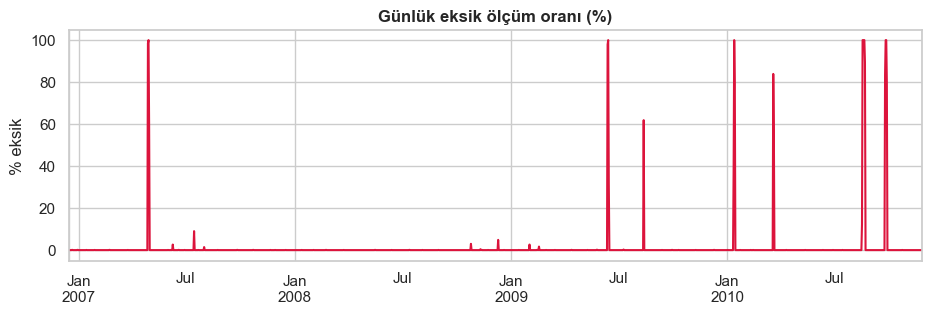

Tamamen eksik gün sayısı: 9


In [4]:
gun_eksik = m.resample("D").mean().mul(100)
ax = gun_eksik.plot(figsize=(11, 3), color="crimson")
ax.set(title="Günlük eksik ölçüm oranı (%)", ylabel="% eksik", xlabel="")
plt.show()
print(f"Tamamen eksik gün sayısı: {(gun_eksik == 100).sum()}")

Eksik değer %1,25, bütün sütunlarda aynı satırlarda. 71 ardışık blok var, en uzunu yaklaşık 5 gün (7.226 dakika), 6 blok 1 günden uzun ve 9 gün hiç ölçüm yok.

Günlük toplam, mevcut dakikaların ortalaması × 24 olarak hesaplanıyor, böylece kısmen eksik bir gün küçük görünmüyor. Hiç ölçümü olmayan günler zaman bazlı interpolasyonla dolduruldu ve `imputed` ile işaretlendi.

## 2. Günlük seri

In [5]:
d = pd.read_csv("../data/daily.csv", index_col=0, parse_dates=True)
print(d.shape, d.index[0].date(), "→", d.index[-1].date(), "· doldurulan gün:", int(d.imputed.sum()))
d.drop(columns="imputed").describe().T.round(2)

(1440, 8) 2006-12-17 → 2010-11-25 · doldurulan gün: 9


,count,mean,std,min,25%,50%,75%,max
kwh,1440.0,26.15,10.02,4.17,19.45,25.86,31.66,79.56
kitchen,1440.0,1.62,1.60,0.00,0.64,1.12,2.23,11.19
laundry,1440.0,1.87,2.10,0.00,0.43,0.69,2.73,12.11
heater,1440.0,9.25,3.70,0.00,6.65,9.26,11.72,23.74
temp,1440.0,11.22,6.38,-5.60,6.70,11.40,16.40,26.60
sunshine_h,1440.0,7.82,4.60,0.00,4.30,8.16,11.60,15.85
precip_mm,1440.0,1.74,3.31,0.00,0.00,0.10,2.00,25.40


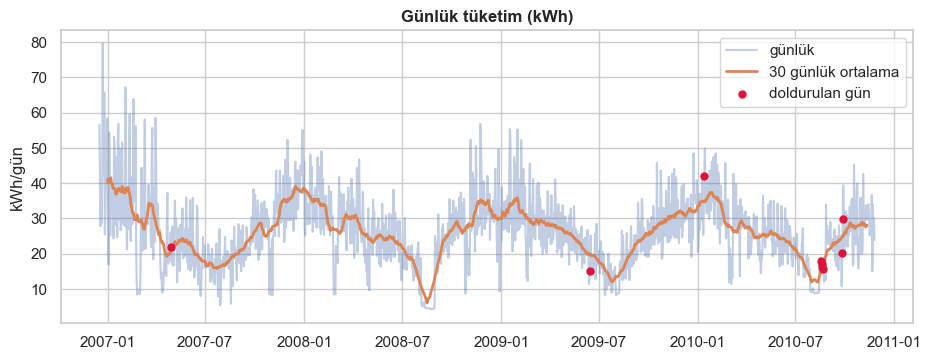

In [6]:
fig, ax = plt.subplots()
ax.plot(d.kwh, alpha=.35, label="günlük")
ax.plot(d.kwh.rolling(30, center=True).mean(), label="30 günlük ortalama", lw=2)
ax.scatter(d.index[d.imputed], d.kwh[d.imputed], color="crimson", zorder=3, s=25, label="doldurulan gün")
ax.set(title="Günlük tüketim (kWh)", ylabel="kWh/gün"); ax.legend(); plt.show()

Yıllık dalga açık: kışın yüksek, yazın düşük. Ağustos belirgin düşük, özellikle 2008'de (2010'da 18-21 Ağustos günleri doldurulmuş). Nedeni veriden doğrulanamıyor. Uzun vadeli bir trend yok, ilk haftalar biraz daha yüksek.

## 3. Mevsimsellik

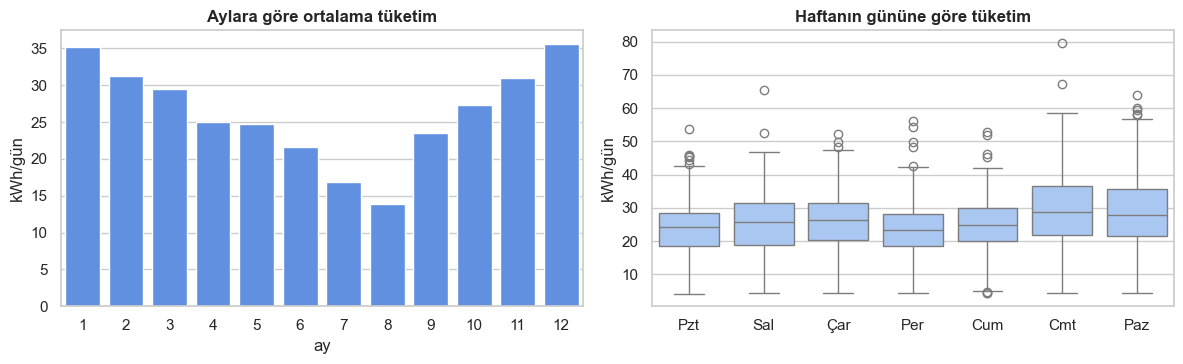

Hafta sonu 29.3 kWh vs hafta içi 24.9 kWh → %18 fark


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(x=d.groupby(d.index.month).kwh.mean().index, y=d.groupby(d.index.month).kwh.mean().values, ax=ax[0], color="#4c8bf5")
ax[0].set(title="Aylara göre ortalama tüketim", xlabel="ay", ylabel="kWh/gün")
sns.boxplot(x=d.index.dayofweek, y=d.kwh, ax=ax[1], color="#9ec5fe")
ax[1].set(title="Haftanın gününe göre tüketim", xlabel="", ylabel="kWh/gün", xticks=range(7), xticklabels=GUNLER)
plt.tight_layout(); plt.show()

hs = d[d.index.dayofweek >= 5].kwh.mean(); hi = d[d.index.dayofweek < 5].kwh.mean()
print(f"Hafta sonu {hs:.1f} kWh vs hafta içi {hi:.1f} kWh → %{(hs/hi-1)*100:.0f} fark")

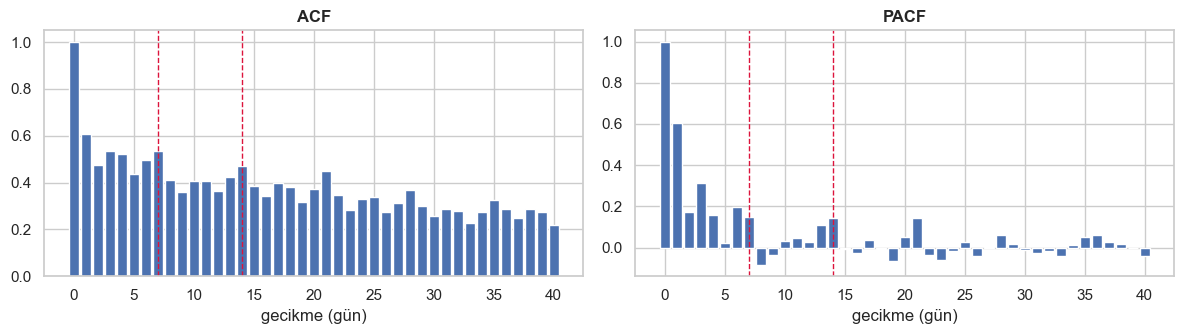

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(range(41), acf(d.kwh, nlags=40)); ax[0].set(title="ACF", xlabel="gecikme (gün)")
ax[1].bar(range(41), pacf(d.kwh, nlags=40)); ax[1].set(title="PACF", xlabel="gecikme (gün)")
for a in ax: a.axvline(7, color="crimson", ls="--", lw=1); a.axvline(14, color="crimson", ls="--", lw=1)
plt.tight_layout(); plt.show()

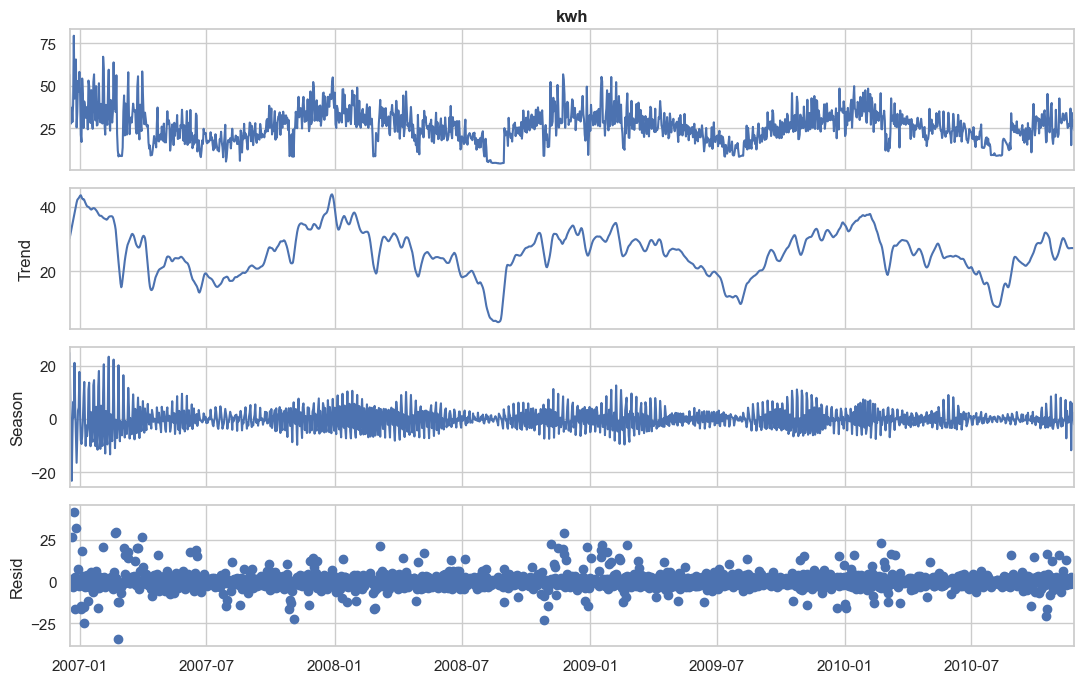

Varyansın payı → mevsimsel (7 gün): %18 · trend: %52 · artık: %30


In [9]:
stl = STL(d.kwh, period=7, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7); plt.tight_layout(); plt.show()
var = lambda s: s.var()
print(f"Varyansın payı → mevsimsel (7 gün): %{var(stl.seasonal)/var(d.kwh)*100:.0f} · trend: %{var(stl.trend)/var(d.kwh)*100:.0f} · artık: %{var(stl.resid)/var(d.kwh)*100:.0f}")

Hafta sonu ortalama %18 yüksek. ACF'de 7, 14, 21. gecikmelerde tepe var, mevsimsel periyot 7. Kış yaklaşık 35 kWh, Ağustos yaklaşık 14 kWh. STL'de varyansın %52'si trend, %18'i haftalık mevsimsellik, %30'u artık.

Baseline: geçen haftanın aynı günü (seasonal naive).

## 4. Durağanlık

In [10]:
def adf(s, ad):
    p = adfuller(s.dropna())[1]; print(f"{ad:<28} ADF p-değeri = {p:.4f} → {'durağan' if p < .05 else 'durağan DEĞİL'}")
adf(d.kwh, "Günlük kWh")
adf(d.kwh.diff(7), "7 gün mevsimsel fark alınmış")

Günlük kWh                   ADF p-değeri = 0.0049 → durağan
7 gün mevsimsel fark alınmış ADF p-değeri = 0.0000 → durağan


ADF'ye göre seri durağan, mevsimsel fark alınınca da (`d=0`). `D=1` ADF'den değil, ACF'deki 7. gecikme tepesinden geliyor. SARIMA grid'inde `D=1` ve periyot 7 sabit, `p, q, P, Q` için grid search var (`tune.py`).

## 5. Hava durumu

kwh           1.00
temp         -0.56
sunshine_h   -0.35
precip_mm    -0.00


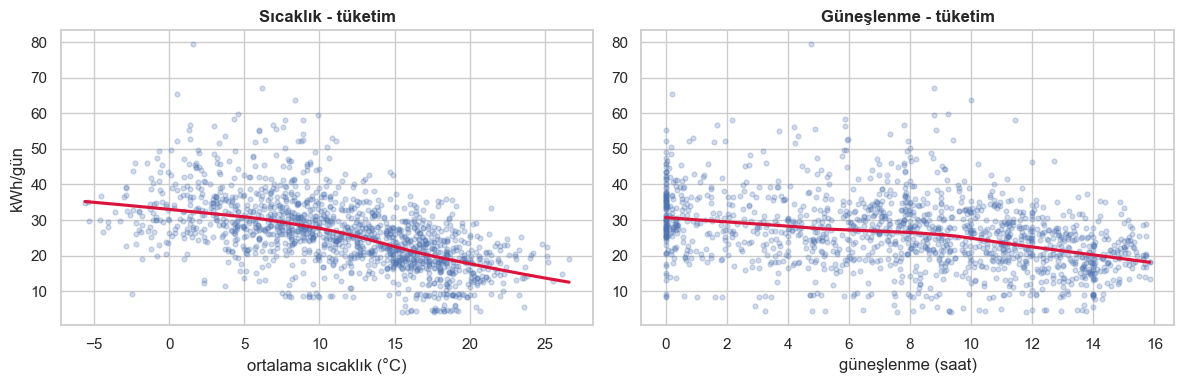

In [11]:
print(d[["kwh", "temp", "sunshine_h", "precip_mm"]].corr().round(2)["kwh"].to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=d, x="temp", y="kwh", lowess=True, scatter_kws={"alpha": .25, "s": 12}, line_kws={"color": "crimson"}, ax=ax[0])
ax[0].set(title="Sıcaklık - tüketim", xlabel="ortalama sıcaklık (°C)", ylabel="kWh/gün")
sns.regplot(data=d, x="sunshine_h", y="kwh", lowess=True, scatter_kws={"alpha": .25, "s": 12}, line_kws={"color": "crimson"}, ax=ax[1])
ax[1].set(title="Güneşlenme - tüketim", xlabel="güneşlenme (saat)", ylabel="")
plt.tight_layout(); plt.show()

In [12]:
# hava mevsimselliğin ötesinde bilgi taşıyor mu? aylık ortalamayı çıkarıp tekrar bak
ay = d.groupby(d.index.month).transform("mean")
art = (d[["kwh", "temp", "sunshine_h"]] - ay[["kwh", "temp", "sunshine_h"]])
print("Mevsimsellik çıkarıldıktan sonra korelasyon:"); print(art.corr().round(2)["kwh"].to_string())

Mevsimsellik çıkarıldıktan sonra korelasyon:
kwh           1.00
temp         -0.06
sunshine_h   -0.03


Sıcaklık ile tüketim arasındaki korelasyon −0,56. Aylık ortalama çıkarılınca −0,06'ya düşüyor: hava sinyali büyük ölçüde aylık mevsimselliğin içinde. Nedenini doğrulamadım; analiz aylık düzeyde, gün gün ince bir etkiyi dışlamaz.

## 6. Alt sayaçlar: enerji nereye gidiyor?

Toplam içindeki pay (%):
mutfak               6.2
çamaşırhane          7.1
su ısıtıcı/klima    35.4
diğer               51.3


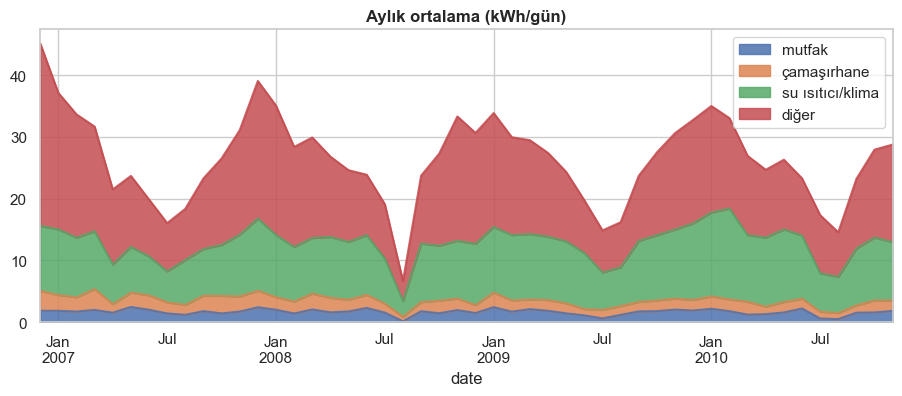

In [13]:
sub = d[["kitchen", "laundry", "heater"]].copy()
sub["diğer"] = d.kwh - sub.sum(axis=1)
sub.columns = ["mutfak", "çamaşırhane", "su ısıtıcı/klima", "diğer"]
pay = (sub.sum() / sub.sum().sum() * 100).round(1); print("Toplam içindeki pay (%):"); print(pay.to_string())
sub.resample("MS").mean().plot.area(figsize=(11, 3.8), title="Aylık ortalama (kWh/gün)", alpha=.85)
plt.show()

Tüketimin yarıdan fazlası alt sayaçlara bağlı olmayan "diğer" kalemde, su ısıtıcı ve klima ikinci büyük pay. Alt sayaçlar gelecek için bilinmediğinden tahmin girdisi değil.